# Notebook 03: Synthetic Data Quality Evaluation
**Project:** Real vs. Synthetic Data: Comparative Analysis and Visualization
**Compared:** cleaned real data vs. the main synthetic data (Gaussian Copula). The two baselines from notebook 02 are included only as reference points in the summary scorecard.

Every result is followed by an interpretation. Where a statistical test is used, we also report an **effect size**, because with about 12,000 rows per dataset even tiny differences give very small p-values, so statistical significance alone says little about practical importance.

## 1. Setup

In [1]:
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.spatial.distance import jensenshannon

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.titlesize": 10, "axes.labelsize": 9})
PAL = {"Real": "#4C78A8", "Synthetic": "#F58518"}

ROOT = Path.cwd()
while not (ROOT / "data").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
FIG_DIR = ROOT / "figures" / "synthetic" / "quality"
RES_DIR = ROOT / "results" / "quality"
for d in (FIG_DIR, RES_DIR):
    d.mkdir(parents=True, exist_ok=True)

real = pd.read_csv(ROOT / "data" / "cleaned" / "online_shoppers_cleaned.csv")
syn = pd.read_csv(ROOT / "data" / "synthetic" / "synthetic_online_shoppers.csv")
boot = pd.read_csv(ROOT / "data" / "synthetic" / "baselines" / "baseline_bootstrap.csv")
indep = pd.read_csv(ROOT / "data" / "synthetic" / "baselines" / "baseline_independent.csv")

NUM = ["Administrative", "Administrative_Duration", "Informational", "Informational_Duration",
       "ProductRelated", "ProductRelated_Duration", "BounceRates", "ExitRates", "PageValues", "SpecialDay",
       "Total_Pages", "Total_Duration", "Avg_Time_Per_Page", "Product_Page_Share"]
CAT = ["Month", "Quarter", "VisitorType", "Weekend", "OperatingSystems", "Browser", "Region",
       "TrafficType", "Session_Length_Band", "Revenue"]
assert list(real.columns) == list(syn.columns)
print("Real:", real.shape, "| Synthetic:", syn.shape, "| numerical:", len(NUM), "| categorical:", len(CAT))

Real: (12199, 24) | Synthetic: (12199, 24) | numerical: 14 | categorical: 10


## 2. Descriptive statistics (real vs. synthetic)

In [2]:
def describe_both(r, s, cols):
    rows = []
    for c in cols:
        for name, d in (("Real", r), ("Synthetic", s)):
            x = d[c]
            rows.append({"column": c, "data": name, "mean": x.mean(), "median": x.median(), "std": x.std(),
                         "variance": x.var(), "min": x.min(), "Q1": x.quantile(.25), "Q3": x.quantile(.75), "max": x.max()})
    return pd.DataFrame(rows).set_index(["column", "data"])

desc = describe_both(real, syn, NUM)
desc.to_csv(RES_DIR / "descriptive_statistics.csv")
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
display(desc)

mean  median       std      variance  \
column                  data                                                  
Administrative          Real          2.340   1.000     3.331        11.095   
                        Synthetic     2.156   2.000     2.601         6.765   
Administrative_Duration Real         79.493   9.000   157.518    24,812.054   
                        Synthetic    61.279  18.671   107.446    11,544.634   
Informational           Real          0.509   0.000     1.276         1.628   
                        Synthetic     0.643   0.000     1.007         1.014   
Informational_Duration  Real         32.767   0.000   120.155    14,437.236   
                        Synthetic    22.264   0.000    47.692     2,274.494   
ProductRelated          Real         31.572  18.000    40.690     1,655.637   
                        Synthetic    32.934  17.000    46.027     2,118.486   
ProductRelated_Duration Real      1,183.082 609.542 1,652.525 2,730,840.396   
                        Synthetic 1,260.716 534.021 1,983.100 3,932,685.319   
BounceRates             Real          0.020   0.003     0.045         0.002   
                        Synthetic     0.014   0.004     0.025         0.001   
ExitRates               Real          0.041   0.025     0.046         0.002   
                        Synthetic     0.040   0.025     0.041         0.002   
PageValues              Real          5.953   0.000    18.658       348.113   
                        Synthetic     5.746   0.000    10.209       104.217   
SpecialDay              Real          0.062   0.000     0.200         0.040   
                        Synthetic     0.060   0.000     0.196         0.038   
Total_Pages             Real         34.421  20.000    42.761     1,828.544   
                        Synthetic    35.733  19.000    47.045     2,213.221   
Total_Duration          Real      1,295.342 691.357 1,749.550 3,060,924.262   
                        Synthetic 1,344.259 623.028 2,015.256 4,061,255.304   
Avg_Time_Per_Page       Real         38.069  30.000    42.785     1,830.515   
                        Synthetic    43.926  31.586    43.337     1,878.124   
Product_Page_Share      Real          0.905   0.962     0.141         0.020   
                        Synthetic     0.879   0.934     0.152         0.023   

                                    min      Q1        Q3        max  
column                  data                                          
Administrative          Real      0.000   0.000     4.000     27.000  
                        Synthetic 0.000   0.000     4.000     27.000  
Administrative_Duration Real      0.000   0.000    94.750  1,178.967  
                        Synthetic 0.000   0.000    84.573  1,178.967  
Informational           Real      0.000   0.000     0.000     24.000  
                        Synthetic 0.000   0.000     2.000      6.000  
Informational_Duration  Real      0.000   0.000     0.000  1,005.421  
                        Synthetic 0.000   0.000    21.945    501.570  
ProductRelated          Real      0.000   8.000    38.000    282.000  
                        Synthetic 1.000   7.000    38.000    282.000  
ProductRelated_Duration Real      0.000 193.708 1,477.565 11,246.177  
                        Synthetic 0.000 205.128 1,361.805 11,246.177  
BounceRates             Real      0.000   0.000     0.017      0.200  
                        Synthetic 0.000   0.000     0.017      0.200  
ExitRates               Real      0.000   0.014     0.048      0.200  
                        Synthetic 0.000   0.013     0.050      0.200  
PageValues              Real      0.000   0.000     0.000    361.764  
                        Synthetic 0.000   0.000    10.087    125.004  
SpecialDay              Real      0.000   0.000     0.000      1.000  
                        Synthetic 0.000   0.000     0.000      1.000  
Total_Pages             Real      1.000   9.000    42.000    323.000  
                        Synthetic 1

In [3]:
# Relative difference of the synthetic statistics from the real ones (percent)
rel = pd.DataFrame({
    s: [(syn[c].agg(s) - real[c].agg(s)) / real[c].agg(s) * 100 if real[c].agg(s) != 0 else np.nan for c in NUM]
    for s in ["mean", "median", "std"]}, index=NUM)
rel.to_csv(RES_DIR / "relative_difference_percent.csv")
display(rel.round(1).rename(columns=lambda c: f"{c} diff %"))

,mean diff %,median diff %,std diff %
Administrative,-7.900,100.000,-21.900
Administrative_Duration,-22.900,107.500,-31.800
Informational,26.400,NaN,-21.100
Informational_Duration,-32.100,NaN,-60.300
ProductRelated,4.300,-5.600,13.100
ProductRelated_Duration,6.600,-12.400,20.000
BounceRates,-31.800,47.800,-44.700
ExitRates,-3.500,1.900,-9.900
PageValues,-3.500,NaN,-45.300
SpecialDay,-3.700,NaN,-1.800


**Interpretation (descriptive statistics).** Means are close for most columns: the relative difference is within about ±7% for Administrative, ProductRelated, ProductRelated_Duration, ExitRates, PageValues, SpecialDay, Total_Pages, Total_Duration and Product_Page_Share. The clearest mean gaps are BounceRates (about −32%), Informational_Duration (−32%), Administrative_Duration (−23%), Informational (+26%) and Avg_Time_Per_Page (+15%).

**Spread and tails are where the synthetic data is weaker.** The standard deviation is lower for most columns, e.g. PageValues 10.2 vs 18.7, Informational_Duration 47.7 vs 120.2 and BounceRates about 0.02 vs 0.05. The maximums show why: synthetic Informational stops at 6 (real 24), Informational_Duration at 502 (real 1005) and PageValues at 125 (real 362). A Gaussian copula with a normal marginal on the log scale cannot reproduce such a long tail. Medians are also off for zero-heavy columns (e.g. synthetic Administrative median 2 vs 1, Informational Q3 2 vs 0), because the zero/non-zero indicator is modelled jointly and not perfectly calibrated. So the synthetic data is good at the centre of the distributions and under-represents extreme sessions. The synthetic minimum for ProductRelated is 1 and for Total_Pages 1 because zero-page sessions were removed from the real data and are rejected in generation.

## 3. Numerical distributions

### 3.1 Histogram and KDE overlays

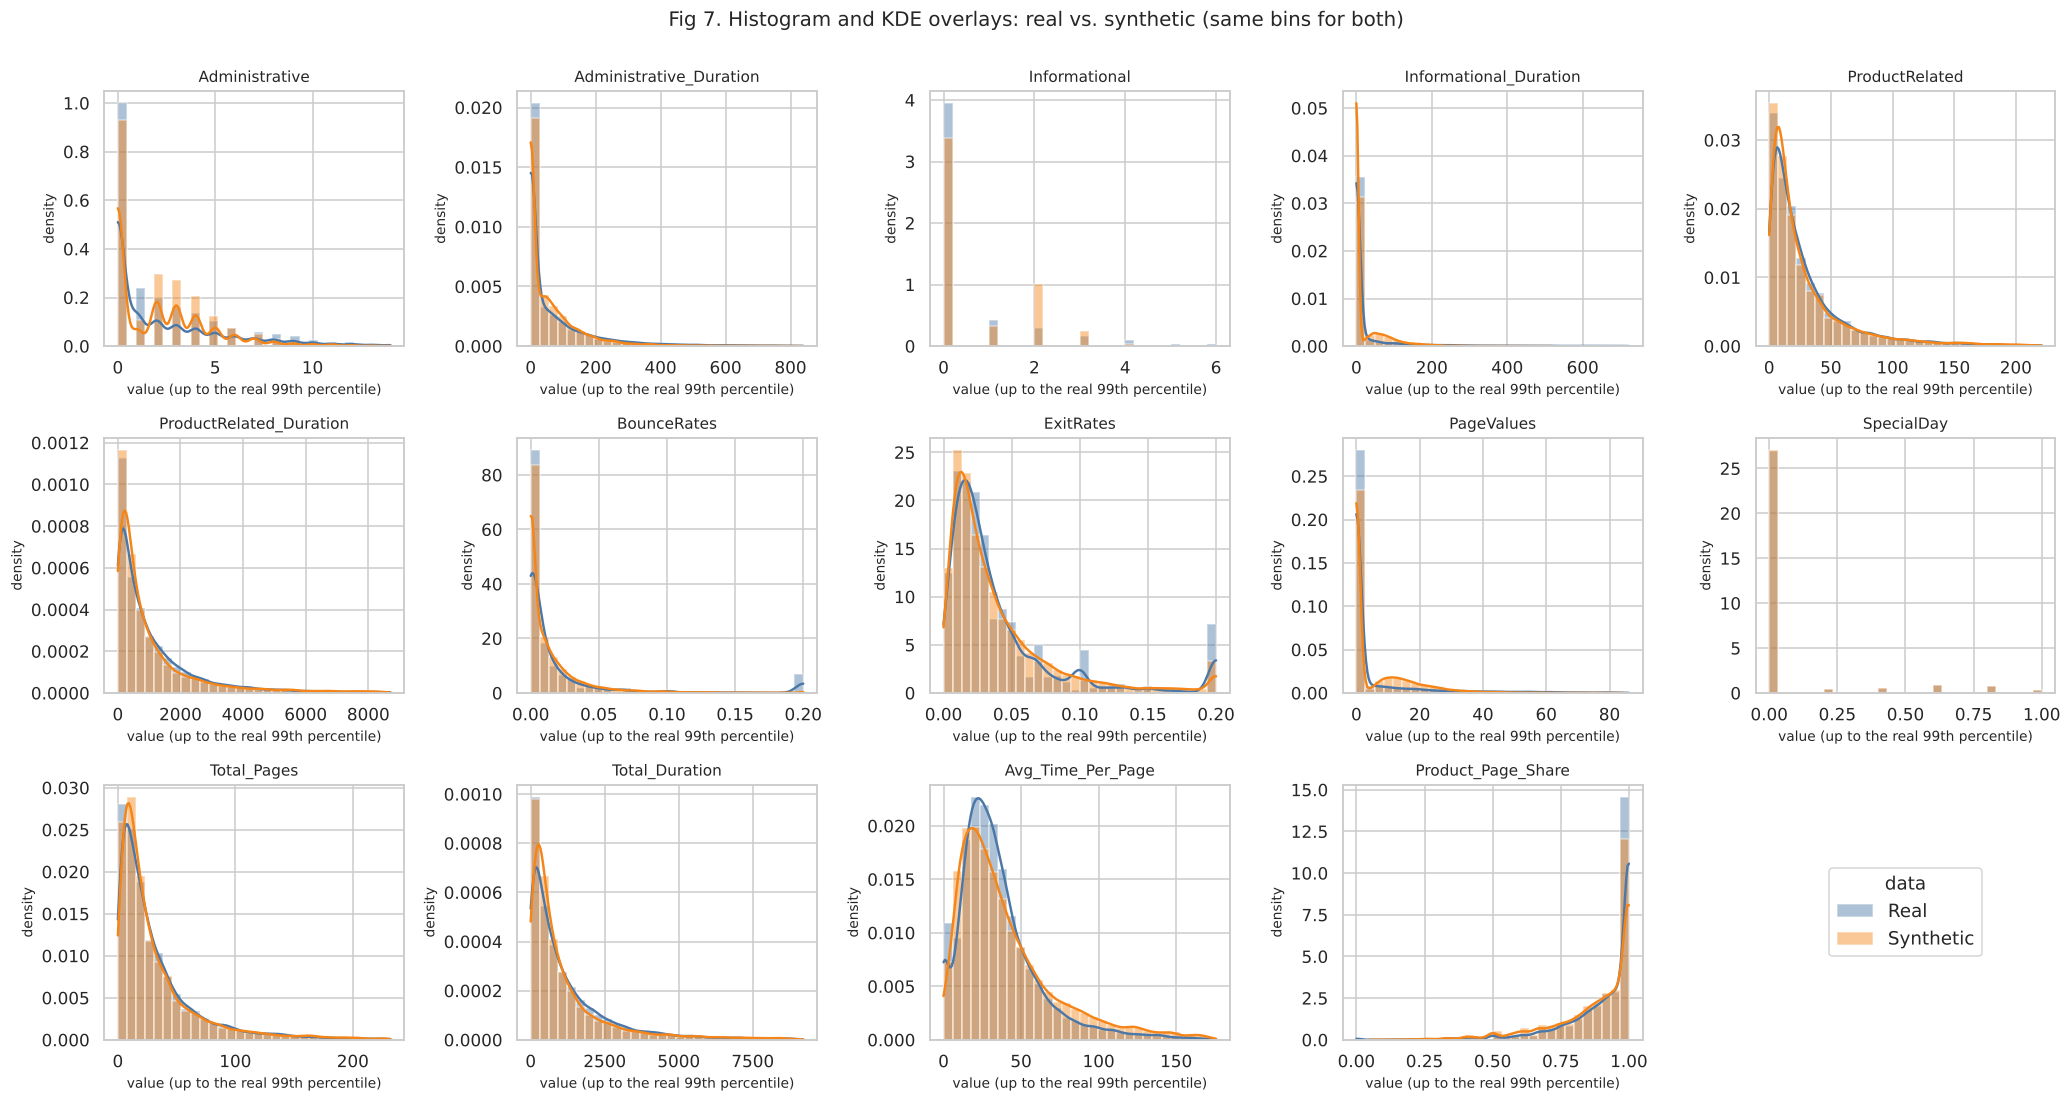

In [4]:
def clip_hi(c):
    return real[c].quantile(0.99)       # show the body of the distribution; the long tail is checked in the box plots and tests

fig, axes = plt.subplots(3, 5, figsize=(19, 10))
for ax, c in zip(axes.ravel(), NUM):
    hi = clip_hi(c); hi = hi if hi > 0 else real[c].max()
    bins = np.linspace(0, hi, 31)
    for name, d in (("Real", real), ("Synthetic", syn)):
        x = d.loc[d[c] <= hi, c]
        ax.hist(x, bins=bins, density=True, alpha=0.45, color=PAL[name], label=name)
        if x.nunique() > 8:
            sns.kdeplot(x, ax=ax, color=PAL[name], clip=(0, hi), bw_adjust=0.8, linewidth=1.6, warn_singular=False)
    ax.set_title(c); ax.set_xlabel("value (up to the real 99th percentile)"); ax.set_ylabel("density")
axes.ravel()[-1].axis("off")
h, l = axes.ravel()[0].get_legend_handles_labels()
axes.ravel()[-1].legend(h[:2], l[:2], loc="center", fontsize=12, title="data")
fig.suptitle("Fig 7. Histogram and KDE overlays: real vs. synthetic (same bins for both)", y=1.0, fontsize=13)
fig.tight_layout(); fig.savefig(FIG_DIR / "fig07_hist_kde_overlay.png", bbox_inches="tight"); plt.show()

**Interpretation (histogram + KDE overlays).** For ProductRelated, ProductRelated_Duration, Total_Pages, Total_Duration and ExitRates the synthetic curves follow the real ones closely, including the long right tail up to the real 99th percentile. The visible mismatches are: (1) the spike of real BounceRates/ExitRates at 0.20 (the capped maximum) is roughly halved in the synthetic data; (2) the synthetic Administrative counts show bumps at 2-4 where the real data decreases smoothly, a side effect of treating the non-zero part as a continuous normal on the log scale and then rounding; (3) synthetic PageValues has a bump around 10-20 that the real data does not have, and it has less mass at exactly zero; (4) Informational_Duration and Informational lose their long tails; (5) SpecialDay was modelled as categorical so its shape is matched. Overall the shapes are recognisably similar, but they are smoother and lighter-tailed than the real ones.

### 3.2 Box plots

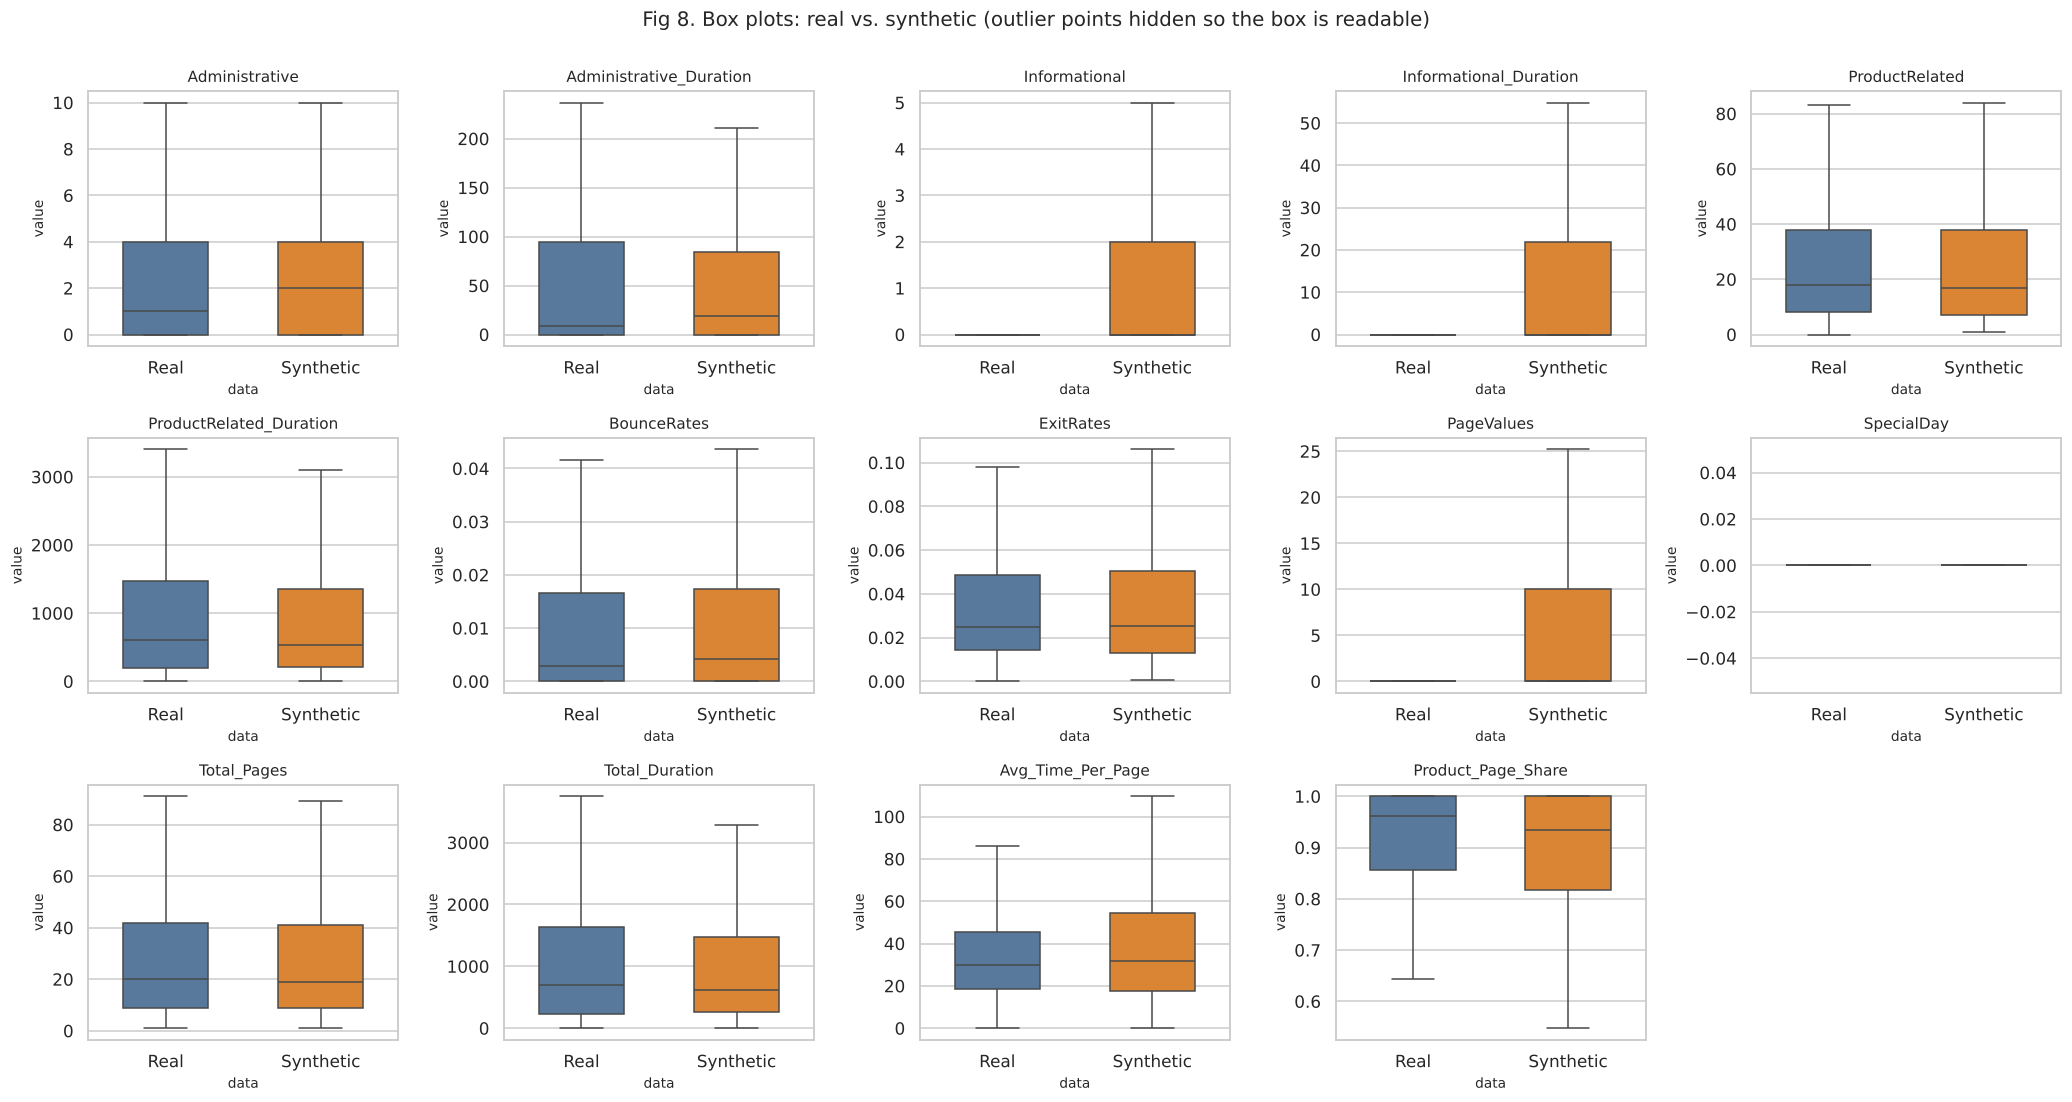

,real p99,synthetic p99,real max,synthetic max
Administrative,14.000,11.000,27.000,27.000
Administrative_Duration,839.100,501.820,"1,178.970","1,178.970"
Informational,6.000,3.000,24.000,6.000
Informational_Duration,722.530,210.680,"1,005.420",501.570
ProductRelated,221.020,277.040,282.000,282.000
ProductRelated_Duration,"8,705.650","11,246.180","11,246.180","11,246.180"
BounceRates,0.200,0.130,0.200,0.200
ExitRates,0.200,0.200,0.200,0.200
PageValues,86.130,42.220,361.760,125.000
SpecialDay,1.000,1.000,1.000,1.000


In [5]:
both = pd.concat([real.assign(data="Real"), syn.assign(data="Synthetic")], ignore_index=True)
fig, axes = plt.subplots(3, 5, figsize=(19, 10))
for ax, c in zip(axes.ravel(), NUM):
    sns.boxplot(data=both, x="data", y=c, hue="data", palette=PAL, ax=ax, showfliers=False, legend=False, width=0.55)
    ax.set_title(c); ax.set_xlabel("data"); ax.set_ylabel("value")
axes.ravel()[-1].axis("off")
fig.suptitle("Fig 8. Box plots: real vs. synthetic (outlier points hidden so the box is readable)", y=1.0, fontsize=13)
fig.tight_layout(); fig.savefig(FIG_DIR / "fig08_boxplots.png", bbox_inches="tight"); plt.show()

# the hidden tails, compared numerically
tail = pd.DataFrame({"real p99": real[NUM].quantile(.99), "synthetic p99": syn[NUM].quantile(.99),
                     "real max": real[NUM].max(), "synthetic max": syn[NUM].max()})
display(tail.round(2))

**Interpretation (box plots).** The boxes (Q1-median-Q3) and whiskers are broadly comparable for the browsing columns (ProductRelated, ProductRelated_Duration, Total_Pages, Total_Duration). Differences show up where the real data has a mass at zero: for Administrative, Administrative_Duration and PageValues the synthetic box is shifted or widened (e.g. PageValues has a non-zero Q3 of about 10 in the synthetic data vs 0 in the real data), meaning the synthetic data has more non-zero values for these columns than the real data in the middle of the distribution but fewer extreme values. The tail table next to the plot confirms that the largest synthetic values are well below the real maximum for Informational, Informational_Duration and PageValues. Fliers are hidden in the plot for readability; the tail table reports them numerically.

### 3.3 Violin plots (log scale)
Box plots hide the spike of exact zeros that most columns have. Violins on a `log1p` axis show it: the wide part at the bottom is the zero mass, and the length of the upper part shows how far the tail reaches.

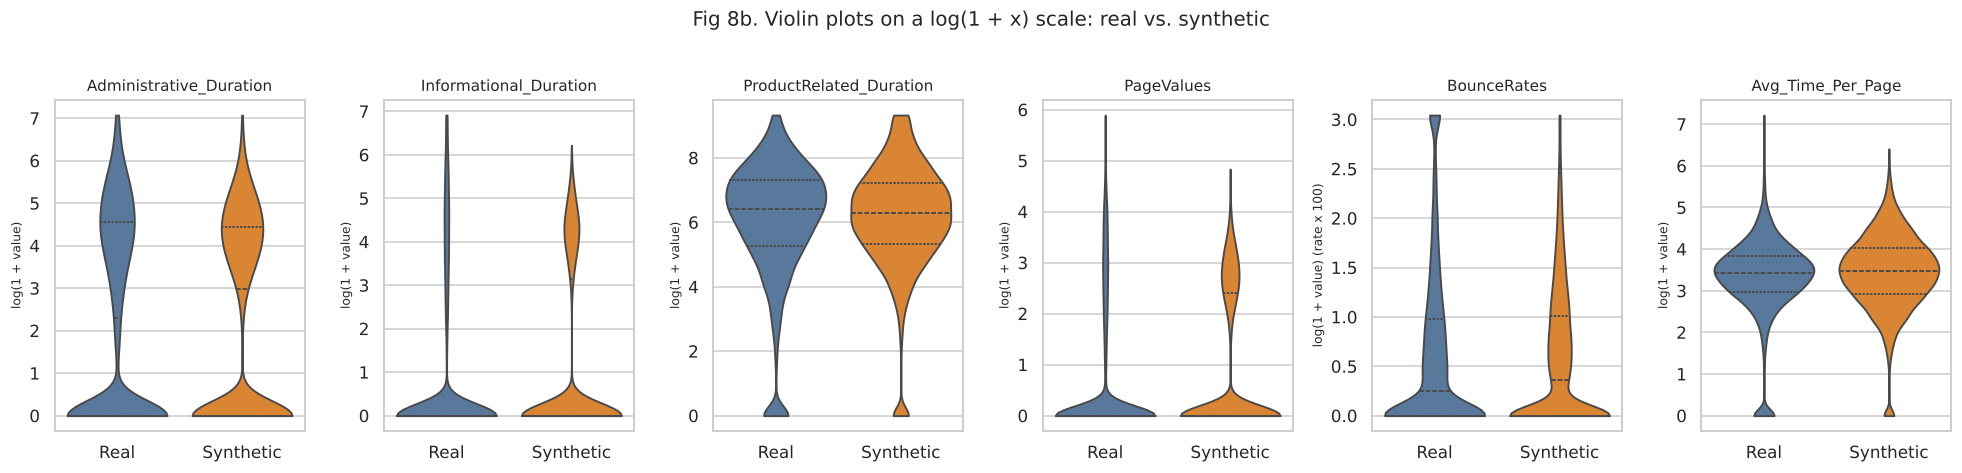

In [6]:
VCOLS = ["Administrative_Duration", "Informational_Duration", "ProductRelated_Duration", "PageValues", "BounceRates", "Avg_Time_Per_Page"]
fig, axes = plt.subplots(1, len(VCOLS), figsize=(18, 4.2))
for ax, c in zip(axes, VCOLS):
    v = both[["data", c]].copy(); v[c] = np.log1p(v[c] * (100 if c == "BounceRates" else 1))
    sns.violinplot(data=v, x="data", y=c, hue="data", palette=PAL, ax=ax, cut=0, inner="quartile", legend=False, density_norm="width")
    ax.set_title(c, fontsize=10); ax.set_xlabel(""); ax.set_ylabel("log(1 + value)" + (" (rate x 100)" if c == "BounceRates" else ""), fontsize=8)
fig.suptitle("Fig 8b. Violin plots on a log(1 + x) scale: real vs. synthetic", y=1.02, fontsize=13)
fig.tight_layout(); fig.savefig(FIG_DIR / "fig08b_violins.png", bbox_inches="tight"); plt.show()

**Interpretation (violin plots).** On the log scale the zero mass (the wide base of each violin) is similar in real and synthetic data for the duration columns, and the bodies of Administrative_Duration and ProductRelated_Duration overlap well; their upper tails reach the same height because both are bounded by the same maximum. The differences are in Informational_Duration and PageValues: the real violins have a very thin tail reaching high values, which the synthetic ones lack (they stop lower), and the synthetic PageValues has a bulge around log values of 2.5 to 3 (raw values of roughly 10 to 20) that the real data does not have. BounceRates has less mass at the top (the real cap of 0.2) in the synthetic data, and Avg_Time_Per_Page is close, with the synthetic median slightly higher. The violins agree with the box plots and tail table: the centre is reproduced reasonably, the extremes are not.

## 4. Categorical distributions

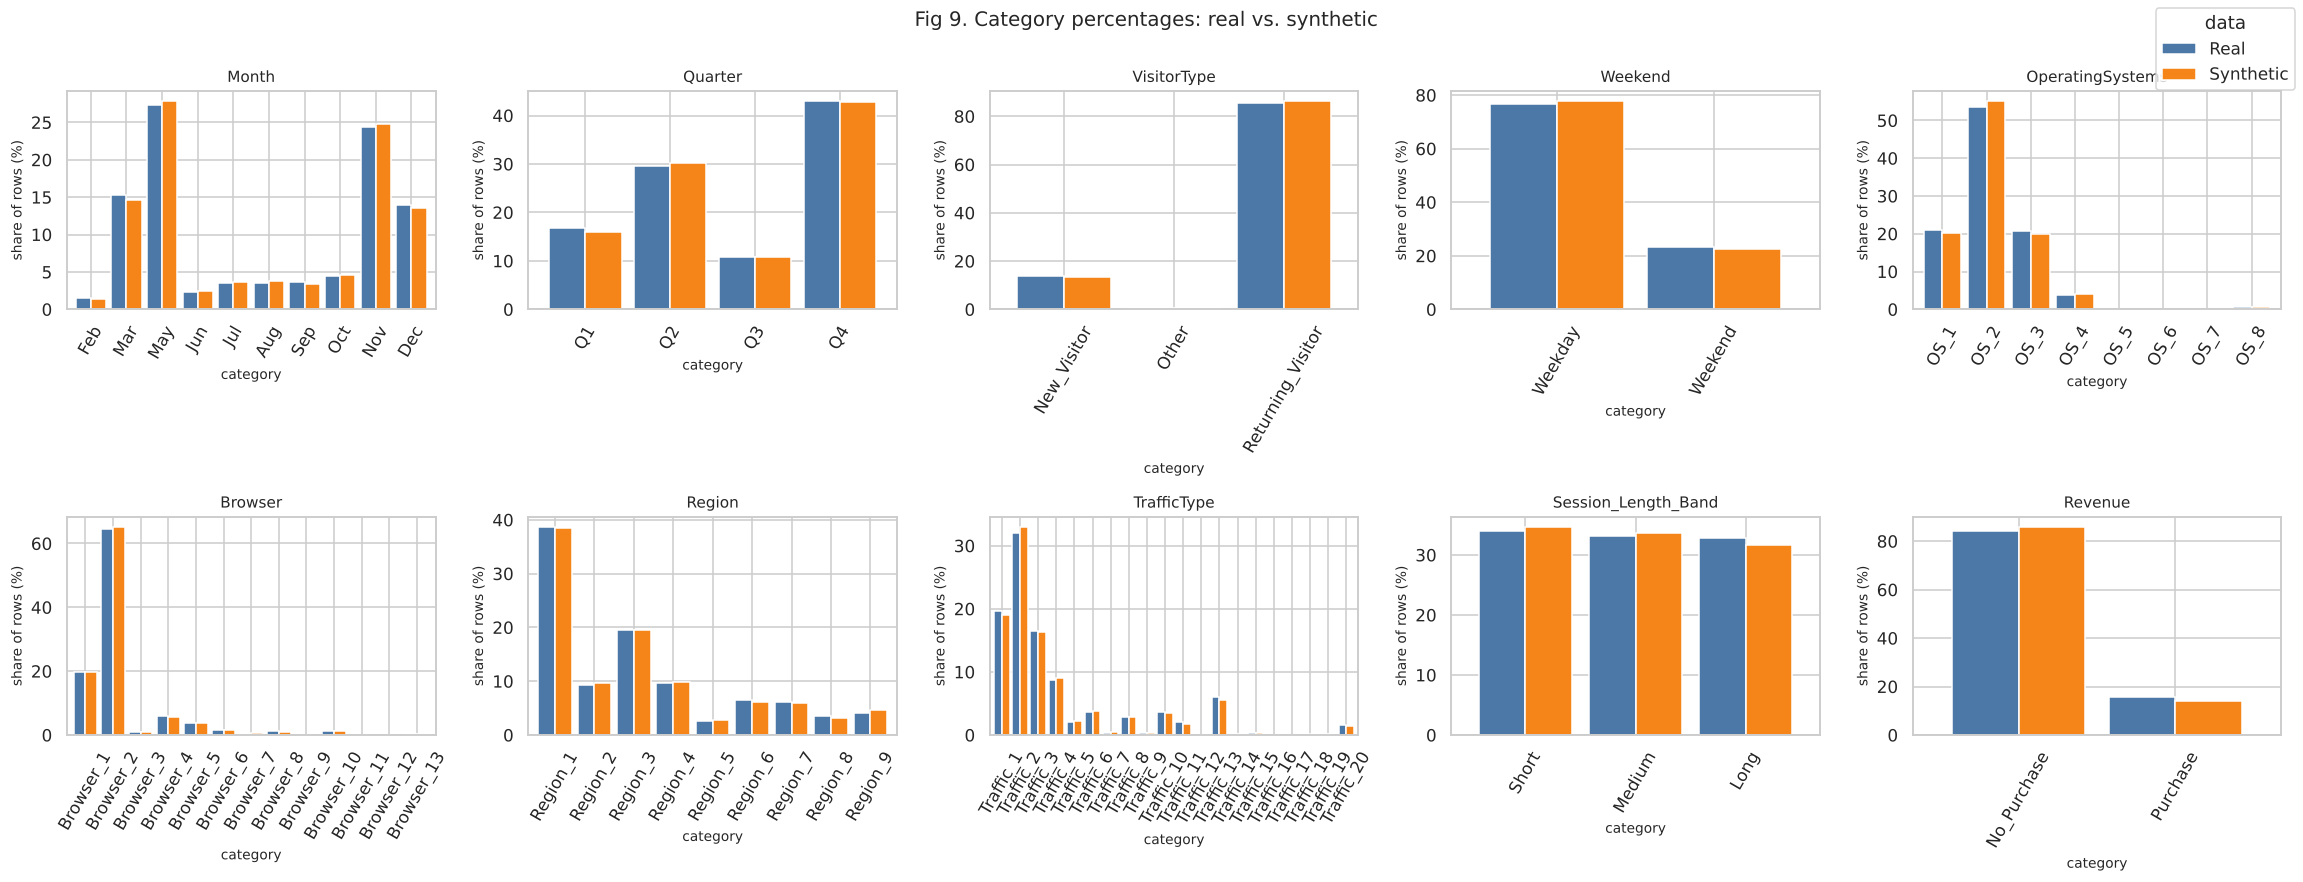

In [7]:
fig, axes = plt.subplots(2, 5, figsize=(21, 8))
cat_pct = {}
for ax, c in zip(axes.ravel(), CAT):
    p = pd.DataFrame({"Real": real[c].value_counts(normalize=True) * 100,
                      "Synthetic": syn[c].value_counts(normalize=True) * 100}).fillna(0)
    order = sorted(p.index, key=lambda v: (len(str(v)) > 0, str(v))) if c not in ("Month", "Quarter", "Session_Length_Band") else None
    if c == "Month":
        order = ["Feb", "Mar", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
    elif c == "Quarter":
        order = ["Q1", "Q2", "Q3", "Q4"]
    elif c == "Session_Length_Band":
        order = ["Short", "Medium", "Long"]
    elif c in ("OperatingSystems", "Browser", "Region", "TrafficType"):
        order = sorted(p.index, key=lambda v: int(str(v).split("_")[1]))
    p = p.loc[order]; cat_pct[c] = p
    p.plot.bar(ax=ax, color=[PAL["Real"], PAL["Synthetic"]], width=0.85, legend=False)
    ax.set_title(c); ax.set_xlabel("category"); ax.set_ylabel("share of rows (%)")
    ax.tick_params(axis="x", rotation=60)
h, l = axes.ravel()[0].get_legend_handles_labels()
fig.legend(h, l, loc="upper right", title="data", fontsize=11)
fig.suptitle("Fig 9. Category percentages: real vs. synthetic", y=1.0, fontsize=13)
fig.tight_layout(); fig.savefig(FIG_DIR / "fig09_categorical_bars.png", bbox_inches="tight"); plt.show()

**Interpretation (categorical comparison).** The side-by-side bars are almost indistinguishable for every categorical column. This is expected, because the copula takes each category's relative frequency directly from the real data. Differences in category share are small, and Cramér's V between real and synthetic is below 0.025 for all columns (see Section 6). Rare levels such as the less common TrafficType and Browser codes are still present in the synthetic data. The one weakness is not visible here: the *combinations* of categories are not preserved (Section 8).

## 5. Correlation structure

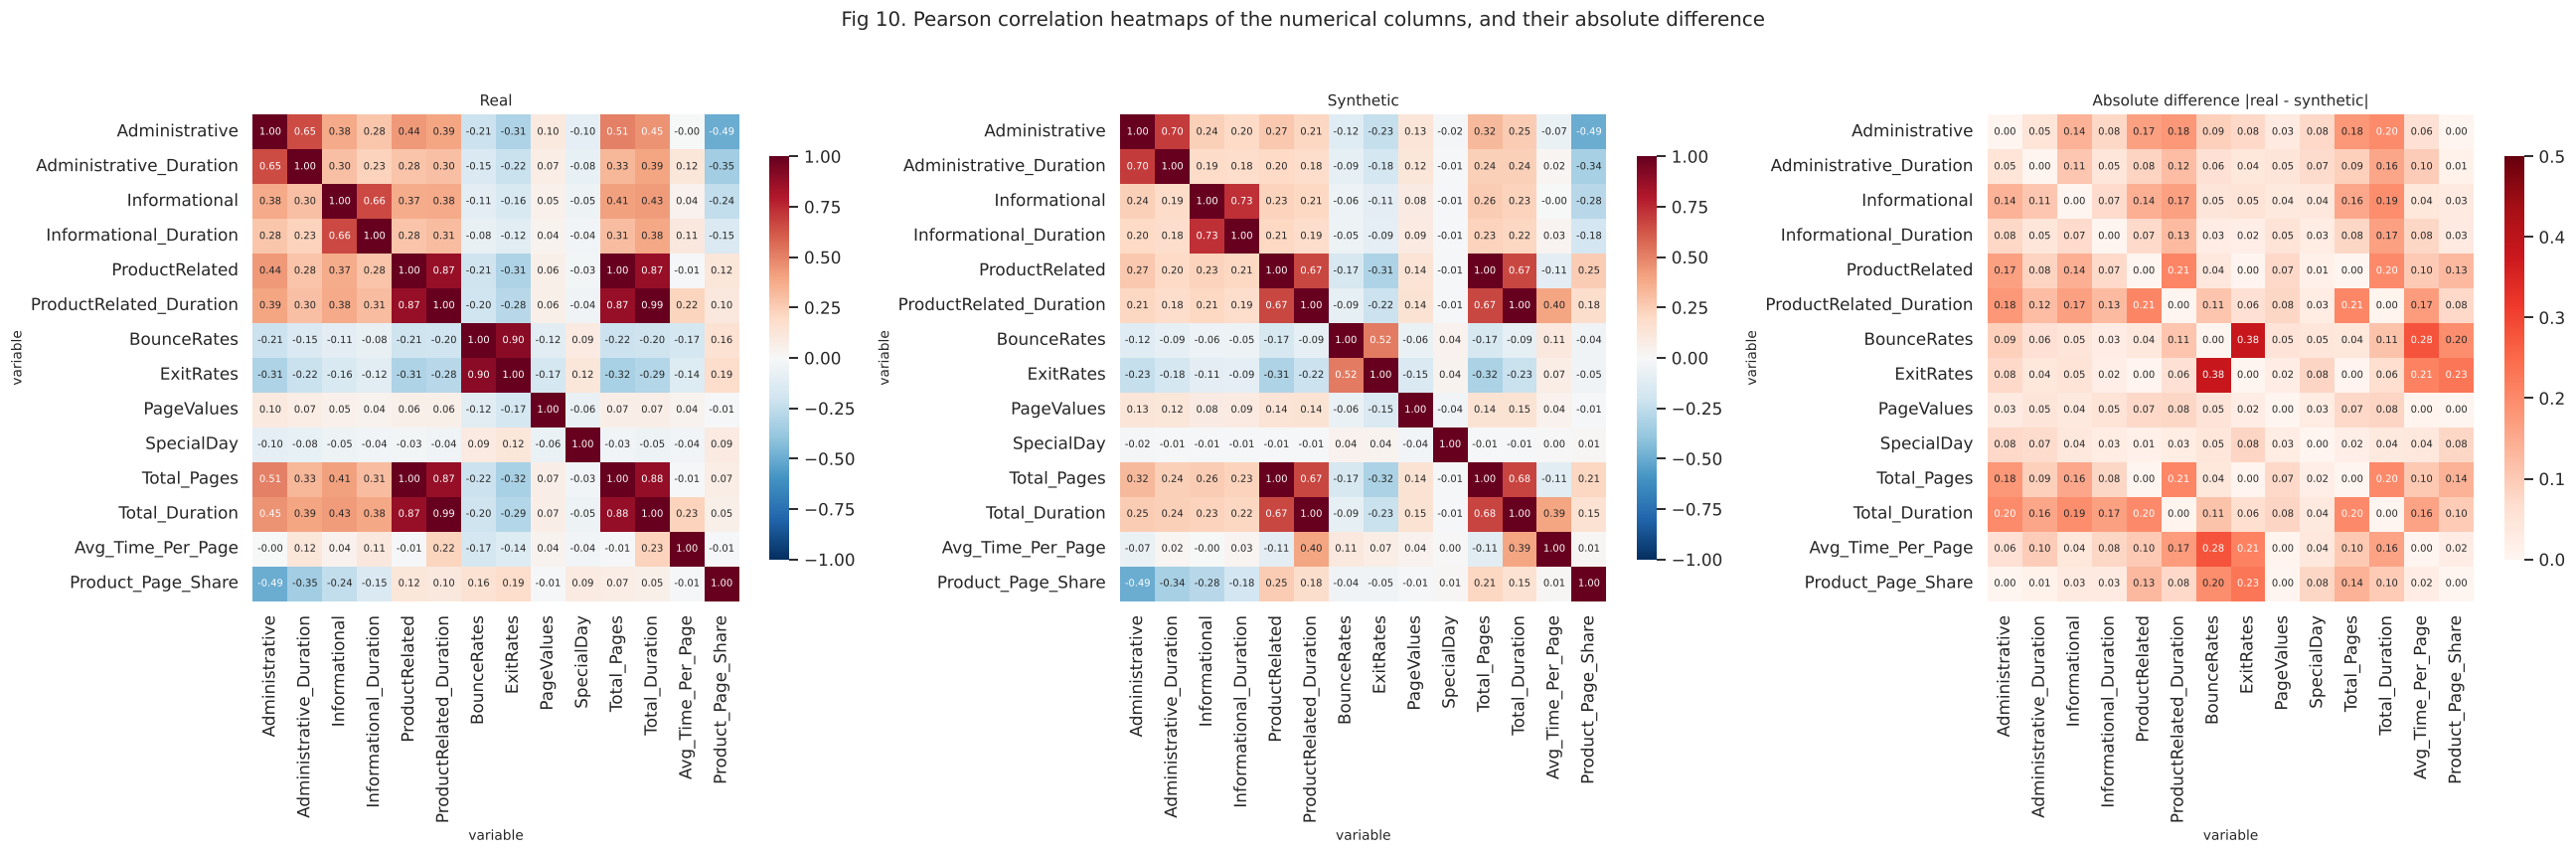

Pearson : mean |diff| = 0.091, max = 0.382, Frobenius norm of difference = 1.554
Spearman: mean |diff| = 0.111, max = 0.370
Pairs with the 8 largest differences:


,pair,real,synthetic,abs_diff
63,BounceRates - ExitRates,0.902,0.519,0.382
68,BounceRates - Avg_Time_Per_Page,-0.174,0.105,0.279
75,ExitRates - Product_Page_Share,0.186,-0.046,0.232
74,ExitRates - Avg_Time_Per_Page,-0.141,0.072,0.213
46,ProductRelated - ProductRelated_Duration,0.875,0.666,0.209
59,ProductRelated_Duration - Total_Pages,0.874,0.668,0.206
85,Total_Pages - Total_Duration,0.876,0.675,0.201
52,ProductRelated - Total_Duration,0.871,0.671,0.200


Strongest real correlations that are preserved or lost (top 8 by |real|):


,pair,real,synthetic,abs_diff
51,ProductRelated - Total_Pages,0.997,0.998,0.001
60,ProductRelated_Duration - Total_Duration,0.993,0.998,0.005
63,BounceRates - ExitRates,0.902,0.519,0.382
85,Total_Pages - Total_Duration,0.876,0.675,0.201
46,ProductRelated - ProductRelated_Duration,0.875,0.666,0.209
59,ProductRelated_Duration - Total_Pages,0.874,0.668,0.206
52,ProductRelated - Total_Duration,0.871,0.671,0.200
25,Informational - Informational_Duration,0.661,0.733,0.072


In [8]:
corr_r, corr_s = real[NUM].corr(), syn[NUM].corr()
corr_d = (corr_r - corr_s).abs()
fig, axes = plt.subplots(1, 3, figsize=(24, 7.5))
for ax, m, t, kw in [(axes[0], corr_r, "Real", dict(cmap="RdBu_r", vmin=-1, vmax=1)),
                     (axes[1], corr_s, "Synthetic", dict(cmap="RdBu_r", vmin=-1, vmax=1)),
                     (axes[2], corr_d, "Absolute difference |real - synthetic|", dict(cmap="Reds", vmin=0, vmax=max(0.5, corr_d.values.max())))]:
    sns.heatmap(m, ax=ax, annot=True, fmt=".2f", annot_kws={"size": 6.5}, square=True, cbar_kws={"shrink": 0.7}, **kw)
    ax.set_title(f"{t}"); ax.set_xlabel("variable"); ax.set_ylabel("variable")
fig.suptitle("Fig 10. Pearson correlation heatmaps of the numerical columns, and their absolute difference", y=1.0, fontsize=13)
fig.tight_layout(); fig.savefig(FIG_DIR / "fig10_correlation_heatmaps.png", bbox_inches="tight"); plt.show()

iu = np.triu_indices(len(NUM), 1)
pairs = pd.DataFrame({"pair": [f"{NUM[i]} - {NUM[j]}" for i, j in zip(*iu)], "real": corr_r.values[iu],
                      "synthetic": corr_s.values[iu], "abs_diff": corr_d.values[iu]}).sort_values("abs_diff", ascending=False)
pairs.to_csv(RES_DIR / "correlation_pairs.csv", index=False)
sp_d = (real[NUM].corr("spearman") - syn[NUM].corr("spearman")).abs().values[iu]
print(f"Pearson : mean |diff| = {pairs.abs_diff.mean():.3f}, max = {pairs.abs_diff.max():.3f}, Frobenius norm of difference = {np.linalg.norm(corr_r - corr_s):.3f}")
print(f"Spearman: mean |diff| = {sp_d.mean():.3f}, max = {sp_d.max():.3f}")
print("Pairs with the 8 largest differences:"); display(pairs.head(8).round(3))
print("Strongest real correlations that are preserved or lost (top 8 by |real|):")
display(pairs.reindex(pairs.real.abs().sort_values(ascending=False).index).head(8).round(3))

**Interpretation (correlation heatmaps).** The synthetic data keeps the overall sign and rough pattern of the real correlation matrix: the block of count/duration columns is positively correlated, BounceRates/ExitRates are negatively related to activity, and Product_Page_Share is negatively related to Administrative/Informational activity. The absolute-difference heatmap shows that the strengths are weakened, though. The largest gaps are BounceRates-ExitRates (0.90 real vs 0.52 synthetic), BounceRates-Avg_Time_Per_Page (sign flipped, -0.17 vs +0.11) and the count-duration pairs for products (ProductRelated vs its duration: 0.87 vs 0.67; Total_Pages vs Total_Duration: 0.88 vs 0.68). The mean absolute difference over all pairs is about 0.09, much better than the 0.22 obtained when columns are sampled independently, but clearly not zero. A copula built on transformed marginals does not reproduce linear correlations exactly after the inverse transformations, rounding and the zero-handling rules.

## 6. Statistical similarity measures

Measures used (all comparing real with synthetic, per column):
- **Kolmogorov-Smirnov (KS) statistic** (largest gap between the two cumulative distributions, 0 to 1) and its p-value, for numerical columns.
- **Wasserstein distance** (average amount one distribution must be moved to match the other); reported in the column's own units and divided by the real standard deviation so columns can be compared.
- **Jensen-Shannon divergence (JSD)** (0 = identical, 1 = completely different, base 2), from histograms with the same bins; bins are quantile-based so zero spikes get their own bin.
- **Chi-square test of homogeneity** for categorical columns, with **Cramer's V** as its effect size, and JSD of the category shares.
- **Correlation-matrix difference** (Section 5).

Our own rule of thumb for "close" (not a standard): KS < 0.05, normalised Wasserstein < 0.05, JSD < 0.02, Cramer's V < 0.05. With 24 tests, a Bonferroni-adjusted level of 0.05 / 24 = 0.002 is used for the p-values.

In [9]:
def js_numeric(a, b, nb=40):
    edges = np.unique(np.quantile(a, np.linspace(0, 1, nb + 1)))
    edges[0], edges[-1] = -np.inf, np.inf
    pa = np.histogram(a, edges)[0] / len(a); pb = np.histogram(b, edges)[0] / len(b)
    return jensenshannon(pa, pb, base=2) ** 2

def numeric_similarity(r, s):
    rows = []
    for c in NUM:
        ks = stats.ks_2samp(r[c], s[c])
        w = stats.wasserstein_distance(r[c], s[c])
        rows.append({"column": c, "KS": ks.statistic, "KS_p": ks.pvalue, "Wasserstein": w,
                     "Wasserstein/std": w / r[c].std(), "JSD": js_numeric(r[c].to_numpy(), s[c].to_numpy())})
    return pd.DataFrame(rows).set_index("column")

def categorical_similarity(r, s):
    rows = []
    for c in CAT:
        levels = sorted(set(r[c]) | set(s[c]))
        tab = np.array([[ (r[c] == l).sum() for l in levels], [ (s[c] == l).sum() for l in levels]])
        keep = tab.sum(axis=0) > 0
        chi2, p, dof, exp = stats.chi2_contingency(tab[:, keep], correction=False)
        n = tab.sum(); v = np.sqrt(chi2 / (n * (min(tab[:, keep].shape) - 1)))
        pr = tab[0] / tab[0].sum(); ps = tab[1] / tab[1].sum()
        rows.append({"column": c, "levels": int(keep.sum()), "chi2": chi2, "dof": dof, "p": p, "Cramers_V": v,
                     "JSD": jensenshannon(pr, ps, base=2) ** 2, "cells_expected<5": int((exp < 5).sum())})
    return pd.DataFrame(rows).set_index("column")

num_sim = numeric_similarity(real, syn)
cat_sim = categorical_similarity(real, syn)
num_sim.to_csv(RES_DIR / "numeric_similarity.csv"); cat_sim.to_csv(RES_DIR / "categorical_similarity.csv")
ALPHA = 0.05 / (len(NUM) + len(CAT))
num_sim["close"] = (num_sim.KS < .05) & (num_sim["Wasserstein/std"] < .05) & (num_sim.JSD < .02)
cat_sim["close"] = (cat_sim.Cramers_V < .05) & (cat_sim.JSD < .02)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
print("Numerical columns (sorted by KS, largest gap first):"); display(num_sim.sort_values("KS", ascending=False))
print("Categorical columns (sorted by Cramer's V):"); display(cat_sim.sort_values("Cramers_V", ascending=False))
print(f"Numerical columns 'close' by our rule: {int(num_sim.close.sum())}/{len(NUM)} | categorical: {int(cat_sim.close.sum())}/{len(CAT)}")
print(f"Tests significant at the Bonferroni level {ALPHA:.4f}: numerical {int((num_sim.KS_p < ALPHA).sum())}/{len(NUM)}, categorical {int((cat_sim.p < ALPHA).sum())}/{len(CAT)}")

Numerical columns (sorted by KS, largest gap first):


,KS,KS_p,Wasserstein,Wasserstein/std,JSD,close
column,,,,,,
PageValues,0.1364,0.0000,3.6256,0.1943,0.0425,False
Informational,0.1270,0.0000,0.3333,0.2612,0.0441,False
Informational_Duration,0.0942,0.0000,21.1506,0.1760,0.0355,False
Administrative,0.0903,0.0000,0.5101,0.1532,0.0267,False
Product_Page_Share,0.0867,0.0000,0.0266,0.1887,0.0086,False
Avg_Time_Per_Page,0.0764,0.0000,7.0747,0.1654,0.0212,False
Total_Duration,0.0525,0.0000,157.9762,0.0903,0.0149,False
BounceRates,0.0472,0.0000,0.0074,0.1641,0.0190,False
Administrative_Duration,0.0458,0.0000,20.4497,0.1298,0.0170,False


Categorical columns (sorted by Cramer's V):


,levels,chi2,dof,p,Cramers_V,JSD,cells_expected<5,close
column,,,,,,,,
TrafficType,20,13.5131,19,0.8113,0.0235,0.0004,6,True
Region,9,11.1002,8,0.1961,0.0213,0.0003,0,True
Revenue,2,10.1184,1,0.0015,0.0204,0.0003,0,True
OperatingSystems,8,7.7570,7,0.3545,0.0178,0.0002,0,True
Month,10,7.4636,9,0.5890,0.0175,0.0002,0,True
Browser,13,4.6378,12,0.9690,0.0138,0.0001,2,True
Weekend,2,3.9849,1,0.0459,0.0128,0.0001,0,True
Session_Length_Band,3,3.6323,2,0.1627,0.0122,0.0001,0,True
Quarter,4,3.1064,3,0.3755,0.0113,0.0001,0,True


Numerical columns 'close' by our rule: 1/14 | categorical: 10/10
Tests significant at the Bonferroni level 0.0021: numerical 13/14, categorical 1/10


**Interpretation (similarity measures).** Numeric columns: the mean KS statistic is 0.064 and the mean Wasserstein distance is 0.13 real standard deviations. Closest columns are SpecialDay, ProductRelated, ExitRates and Total_Pages (KS about 0.03 or below); weakest are PageValues (KS 0.136), Informational (0.127), Informational_Duration (0.094), Administrative (0.090) and Product_Page_Share (0.087). All KS p-values except SpecialDay are below the Bonferroni level of 0.0021, but with 12,000 rows per sample this mostly reflects power, so effect sizes matter more: by our own rule of thumb (KS < 0.05, W/std < 0.05, JSD < 0.02) only a few columns count as close. Categorical columns: Cramér's V is between 0.010 and 0.024 and JSD is below 0.0005 for every column. The chi-square test is not significant at the Bonferroni level (0.0021) for any column except Revenue (p = 0.0015), where the effect size is still tiny (V = 0.02); Weekend (p = 0.046) is not significant after correction.

**An honest caveat:** the independent-sampling baseline has a similar mean KS (0.059 vs our 0.064), so on marginal distributions alone the copula is no better than sampling each column separately. The copula's advantage is on relationships between columns (Section 5).

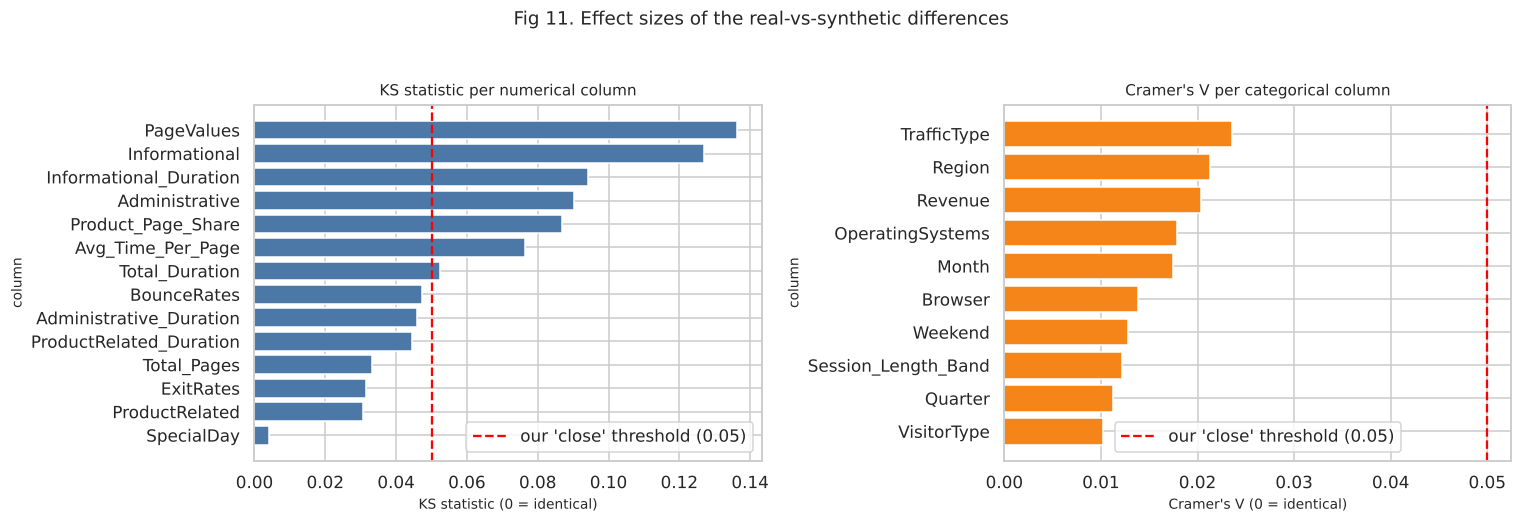

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
ns = num_sim.sort_values("KS")
axes[0].barh(ns.index, ns["KS"], color="#4C78A8"); axes[0].axvline(0.05, color="red", ls="--", label="our 'close' threshold (0.05)")
axes[0].set_title("KS statistic per numerical column"); axes[0].set_xlabel("KS statistic (0 = identical)"); axes[0].set_ylabel("column"); axes[0].legend()
cs = cat_sim.sort_values("Cramers_V")
axes[1].barh(cs.index, cs["Cramers_V"], color="#F58518"); axes[1].axvline(0.05, color="red", ls="--", label="our 'close' threshold (0.05)")
axes[1].set_title("Cramer's V per categorical column"); axes[1].set_xlabel("Cramer's V (0 = identical)"); axes[1].set_ylabel("column"); axes[1].legend()
fig.suptitle("Fig 11. Effect sizes of the real-vs-synthetic differences", y=1.03, fontsize=12)
fig.tight_layout(); fig.savefig(FIG_DIR / "fig11_effect_sizes.png", bbox_inches="tight"); plt.show()

## 7. Do the key relationships survive? (purchase behaviour)

PageValues  ProductRelated_Duration  Total_Pages  \
data      Revenue                                                         
Real      No_Purchase      2.0010               1,061.3940      31.2880   
          Purchase        27.2650               1,839.4190      51.3180   
Synthetic No_Purchase      4.8820               1,194.2690      34.3620   
          Purchase        10.9760               1,662.5440      44.0250   

                       BounceRates  ExitRates  
data      Revenue                              
Real      No_Purchase       0.0230     0.0450  
          Purchase          0.0050     0.0200  
Synthetic No_Purchase       0.0140     0.0410  
          Purchase          0.0110     0.0310

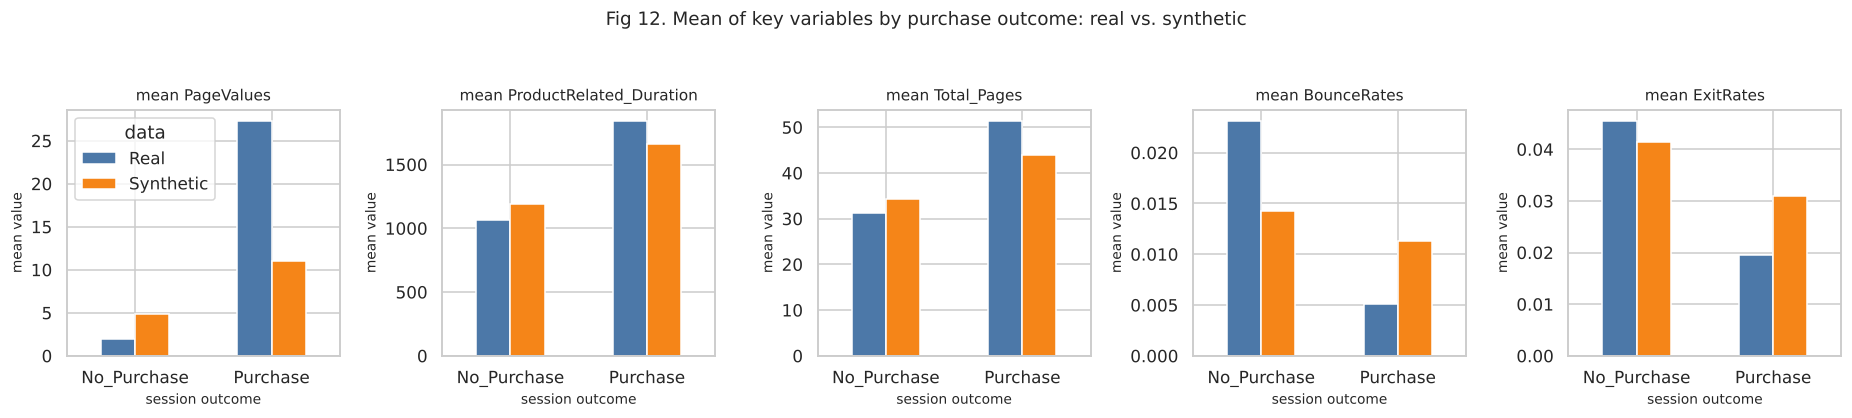

Real  Synthetic  diff (pp)
VisitorType New_Visitor       24.9300    16.9900    -7.9400
            Other             19.7500    21.3300     1.5800
            Returning_Visitor 14.1000    13.7100    -0.3900
Weekend     Weekday           15.0800    14.2600    -0.8200
            Weekend           17.4600    13.9300    -3.5300
Quarter     Q1                 9.5500    11.4900     1.9400
            Q2                10.9100    13.7100     2.7900
            Q3                17.3600    15.1400    -2.2300
            Q4                20.8400    15.3000    -5.5500

Overall purchase rate: real 15.64%, synthetic 14.19%


In [11]:
KEY = ["PageValues", "ProductRelated_Duration", "Total_Pages", "BounceRates", "ExitRates"]
grp = pd.concat({n: d.groupby("Revenue")[KEY].mean() for n, d in (("Real", real), ("Synthetic", syn))}, names=["data"])
display(grp.round(3))
fig, axes = plt.subplots(1, len(KEY), figsize=(17, 3.6))
for ax, c in zip(axes, KEY):
    t = pd.DataFrame({n: d.groupby("Revenue")[c].mean() for n, d in (("Real", real), ("Synthetic", syn))})
    t.plot.bar(ax=ax, color=[PAL["Real"], PAL["Synthetic"]], legend=False)
    ax.set_title(f"mean {c}"); ax.set_xlabel("session outcome"); ax.set_ylabel("mean value"); ax.tick_params(axis="x", rotation=0)
axes[0].legend(title="data")
fig.suptitle("Fig 12. Mean of key variables by purchase outcome: real vs. synthetic", y=1.05, fontsize=12)
fig.tight_layout(); fig.savefig(FIG_DIR / "fig12_key_relationships.png", bbox_inches="tight"); plt.show()

rate = pd.concat({g: pd.DataFrame({n: (d.groupby(g)["Revenue"].apply(lambda s: (s == "Purchase").mean()) * 100)
                                   for n, d in (("Real", real), ("Synthetic", syn))}) for g in ["VisitorType", "Weekend", "Quarter"]})
rate["diff (pp)"] = rate["Synthetic"] - rate["Real"]
display(rate.round(2))
print(f"Overall purchase rate: real {(real.Revenue == 'Purchase').mean() * 100:.2f}%, synthetic {(syn.Revenue == 'Purchase').mean() * 100:.2f}%")

**Interpretation (key relationships by purchase).** The synthetic data keeps the direction of the main relationships: purchasing sessions have higher PageValues, longer product-page time, more pages and lower bounce/exit rates than non-purchasing ones. The strength is reduced though. Mean PageValues for purchasing sessions is 27.3 real vs 11.0 synthetic, and for non-purchasing sessions 2.0 vs 4.9, so the gap between the two groups shrinks from about 25 to about 6. Bounce rate barely separates the groups in the synthetic data (0.011 vs 0.014; real 0.005 vs 0.023). The overall purchase rate is 14.19% vs 15.64%. By group, the largest gaps are New_Visitor (24.9% real vs 17.0% synthetic, -7.9 pp), Q4 (20.8% vs 15.3%, -5.6 pp) and Weekend (17.5% vs 13.9%, -3.5 pp); Q1 and Q2 are higher in the synthetic data (+1.9 and +2.8 pp). Analyses of what drives purchases will therefore find weaker effects on the synthetic data than on the real data.

## 8. Association between categorical columns

In [12]:
def cramers(x, y):
    t = pd.crosstab(x, y)
    chi2 = stats.chi2_contingency(t, correction=False)[0]
    return np.sqrt(chi2 / (t.values.sum() * (min(t.shape) - 1)))

pairs_c = [(CAT[i], CAT[j]) for i in range(len(CAT)) for j in range(i + 1, len(CAT))]
assoc = pd.DataFrame([{"pair": f"{a} - {b}", "real": cramers(real[a], real[b]), "synthetic": cramers(syn[a], syn[b])} for a, b in pairs_c])
assoc["abs_diff"] = (assoc.real - assoc.synthetic).abs()
assoc.sort_values("abs_diff", ascending=False).to_csv(RES_DIR / "categorical_associations.csv", index=False)
print(f"Cramer's V association: mean |diff| = {assoc.abs_diff.mean():.3f}, max = {assoc.abs_diff.max():.3f}")
display(assoc.sort_values("abs_diff", ascending=False).head(6).round(3))

Cramer's V association: mean |diff| = 0.101, max = 0.475


,pair,real,synthetic,abs_diff
30,OperatingSystems - Browser,0.5950,0.1200,0.4750
19,VisitorType - Browser,0.5040,0.0400,0.4650
18,VisitorType - OperatingSystems,0.4540,0.0230,0.4310
21,VisitorType - TrafficType,0.3760,0.0490,0.3270
14,Quarter - TrafficType,0.3080,0.0380,0.2700
6,Month - TrafficType,0.2000,0.0370,0.1630


**Interpretation (categorical associations).** This is the main weakness of the synthetic data. The real data has strong dependencies between categorical columns, e.g. OperatingSystems-Browser (Cramér's V 0.59), VisitorType-Browser (0.50), VisitorType-OperatingSystems (0.45), VisitorType-TrafficType (0.38) and Quarter-TrafficType (0.31). In the synthetic data these are nearly gone (0.12, 0.04, 0.02, 0.05 and 0.04). The mean absolute difference over all pairs is 0.10 and the maximum is 0.475. The reason is that the Gaussian copula treats categories as ordered by frequency and encodes them as numbers, which cannot represent associations between unordered category labels. Any analysis that relies on category combinations (e.g. traffic source by visitor type) will not be reliable on this synthetic data.

## 9. Privacy and novelty check (exact duplicates)

In [13]:
def dup_report(s, name):
    cols = list(real.columns)
    fcols = real.select_dtypes("float").columns
    rr = real.copy(); rr[fcols] = rr[fcols].round(6)
    ss = s.copy();    ss[fcols] = ss[fcols].round(6)
    full = int(ss.merge(rr.drop_duplicates(), how="inner", on=cols).shape[0])
    base_cols = [c for c in cols if c not in ("Total_Pages", "Total_Duration", "Avg_Time_Per_Page", "Product_Page_Share",
                                              "Quarter", "Session_Length_Band")]
    basec = int(ss.merge(rr[base_cols].drop_duplicates(), how="inner", on=base_cols).shape[0])
    return {"dataset": name, "rows": len(s), "rows identical to a real row (all 24 cols)": full,
            "same on the 18 generated cols": basec, "% identical": round(100 * full / len(s), 2),
            "duplicate rows inside the dataset": int(ss.duplicated().sum())}

priv = pd.DataFrame([dup_report(syn, "Gaussian Copula (main)"), dup_report(boot, "Bootstrap (baseline)"),
                     dup_report(indep, "Independent (baseline)")]).set_index("dataset")
priv.to_csv(RES_DIR / "privacy_duplicates.csv"); display(priv)

# a stricter look: closeness to real records on standardised numeric columns (log scale)
from sklearn.neighbors import NearestNeighbors
Z = lambda d: np.log1p(d[NUM[:9]]).to_numpy()
mu, sd = Z(real).mean(0), Z(real).std(0)
nn = NearestNeighbors(n_neighbors=2).fit((Z(real) - mu) / sd)
d_syn = nn.kneighbors((Z(syn) - mu) / sd, n_neighbors=1)[0].ravel()
d_real = nn.kneighbors((Z(real) - mu) / sd, n_neighbors=2)[0][:, 1]            # real record to its nearest OTHER real record
print(f"Median distance to the closest real record: synthetic {np.median(d_syn):.3f} vs. real-to-other-real {np.median(d_real):.3f}")
print(f"Share of synthetic rows closer to a real record than 5% of real records are to each other: "
      f"{(d_syn < np.quantile(d_real, .05)).mean() * 100:.1f}%")

,rows,rows identical to a real row (all 24 cols),same on the 18 generated cols,% identical,duplicate rows inside the dataset
dataset,,,,,
Gaussian Copula (main),12199,0,0,0.0000,0
Bootstrap (baseline),12199,12199,12199,100.0000,4496
Independent (baseline),12199,0,0,0.0000,0


Median distance to the closest real record: synthetic 0.446 vs. real-to-other-real 0.233
Share of synthetic rows closer to a real record than 5% of real records are to each other: 0.0%


**Interpretation (privacy and novelty).** None of the 12,199 synthetic rows is an exact copy of a real row (0 matches on all 24 columns and 0 on the 18 generated columns), and the synthetic data has no duplicate rows inside itself. As a positive control, the bootstrap baseline, which resamples real rows, is detected as 100% copies, so the check does work. The nearest-neighbour check points the same way: the median distance from a synthetic row to its closest real record (0.446 on standardised log scale) is about twice the distance between a real record and its nearest *other* real record (0.233), and 0.0% of synthetic rows are closer to a real record than the closest 5% of real-to-real pairs. So there is no sign of memorised or near-copied records. An exact-duplicate check is only a minimum test: it is not a formal privacy guarantee such as differential privacy.

## 10. Summary scorecard

In [14]:
def scorecard(s, name):
    fc = real.select_dtypes("float").columns
    r6 = real.copy(); r6[fc] = r6[fc].round(6); s6 = s.copy(); s6[fc] = s6[fc].round(6)
    ns, cs = numeric_similarity(real, s), categorical_similarity(real, s)
    cr = real[NUM].corr(); cs_ = s[NUM].corr()
    return {"generator": name, "mean KS": ns.KS.mean(), "mean Wasserstein/std": ns["Wasserstein/std"].mean(),
            "mean JSD (num)": ns.JSD.mean(), "mean Cramer's V": cs.Cramers_V.mean(), "mean JSD (cat)": cs.JSD.mean(),
            "mean |d Pearson|": (cr - cs_).abs().values[iu].mean(),
            "mean |d Spearman|": (real[NUM].corr("spearman") - s[NUM].corr("spearman")).abs().values[iu].mean(),
            "purchase rate %": (s.Revenue == "Purchase").mean() * 100,
            "% rows identical to real": 100 * s6.merge(r6.drop_duplicates(), how="inner", on=list(real.columns)).shape[0] / len(s)}
score = pd.DataFrame([scorecard(syn, "Gaussian Copula (main)"), scorecard(boot, "Bootstrap (baseline)"),
                      scorecard(indep, "Independent (baseline)")]).set_index("generator")
score.to_csv(RES_DIR / "scorecard.csv")
display(score.round(3))
print(f"Real purchase rate: {(real.Revenue == 'Purchase').mean() * 100:.2f}%")

,mean KS,mean Wasserstein/std,mean JSD (num),mean Cramer's V,mean JSD (cat),mean |d Pearson|,mean |d Spearman|,purchase rate %,% rows identical to real
generator,,,,,,,,,
Gaussian Copula (main),0.0640,0.1290,0.0200,0.0160,0.0000,0.0910,0.1110,14.1900,0.0000
Bootstrap (baseline),0.0060,0.0090,0.0000,0.0090,0.0000,0.0060,0.0050,15.5670,100.0000
Independent (baseline),0.0590,0.2120,0.0190,0.0150,0.0000,0.2200,0.2950,14.9680,0.0000


Real purchase rate: 15.64%


**Interpretation (scorecard).** The bootstrap baseline scores almost perfectly on every fidelity measure but 100% of its rows are copies of real rows, so it is useless as synthetic data and serves only as an upper reference. The independent baseline has no copies but destroys relationships (mean |ΔPearson| 0.22, |ΔSpearman| 0.30). The Gaussian copula sits between them: no copies, relationships much better preserved than independent sampling (0.09 and 0.11) and a lower Wasserstein/std (0.13 vs 0.21), but a mean KS that is not better (0.064 vs 0.059). Its purchase rate is 14.19% against 15.64% in the real data.

## 11. Overall verdict of Phase 4

## Verdict of Phase 4

**Strong points.** (1) Categorical marginals match very well (Cramér's V < 0.025). (2) The bulk of the numeric distributions is reproduced and the generated data is valid by construction. (3) Numeric relationships are partly preserved, clearly better than independent sampling. (4) No real row is copied (the bootstrap control confirms the check works) and synthetic rows are not unusually close to real ones.

**Weak points.** (1) The extreme tail is truncated for Informational, Informational_Duration and PageValues. (2) Strong numeric links are weakened (BounceRates-ExitRates 0.90 to 0.52; count-duration about 0.87 to 0.67). (3) Associations between categorical columns are largely lost (mean |ΔV| 0.10, max 0.475). (4) The purchase signal is weaker (mean PageValues for purchases 27.3 vs 11.0).

**Consequence for the next phases.** The synthetic data is adequate for describing overall traffic patterns and the distribution of categories, but conclusions about purchase drivers and category combinations on the synthetic data should be treated with care. In the comparative analysis (Phase 6) we report these differences as they are and do not tune the generator to hide them. We kept the generator and seed unchanged so that results are reproducible.